In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline

In [2]:
from pathlib import Path
DATA_PATH = Path('Datasets')

reviews = pd.read_csv(DATA_PATH / 'olist_order_reviews_dataset.csv')

print(f"Reviews cargadas: {reviews.shape}")
print(reviews['review_score'].value_counts().sort_index())

Reviews cargadas: (99224, 7)
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64


In [3]:
# el 3 es muy ambiguo, lo saco
df = reviews[reviews['review_score'] != 3].copy()

# Etiqueta binaria
df['sentimiento'] = (df['review_score'] >= 4).astype(int)  # 1=positivo, 0=negativo

# junto título y comentario en un solo campo de texto
df['texto'] = df['review_comment_title'].fillna('') + ' ' + df['review_comment_message'].fillna('')
df['texto'] = df['texto'].str.strip()

# Eliminar filas sin texto
df = df[df['texto'] != '']

print(f"Reviews con texto: {len(df)}")
print(f"Positivas: {df['sentimiento'].sum()} | Negativas: {(df['sentimiento']==0).sum()}")

Reviews con texto: 39044
Positivas: 28050 | Negativas: 10994


In [ ]:
# acá uso split aleatorio, no hace falta ordenar por fecha para sentimientos
X_train, X_test, y_train, y_test = train_test_split(
    df['texto'], df['sentimiento'], test_size=0.2, random_state=42
)

# stopwords en portugués — las más comunes que no aportan significado
stopwords_pt = [
    'de', 'a', 'o', 'que', 'e', 'do', 'da', 'em', 'um', 'para',
    'con', 'uma', 'os', 'no', 'se', 'na', 'por', 'mais', 'as',
    'dos', 'como', 'mas', 'ao', 'ele', 'das', 'seu', 'sua', 'ou',
    'quando', 'muito', 'nos', 'já', 'eu', 'também', 'só', 'pelo',
    'pela', 'até', 'isso', 'ela', 'entre', 'depois', 'sem', 'mesmo'
]
# no incluyo "não" en las stopwords porque cambia el significado
# "bom" vs "não bom" son cosas muy distintas

vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words=stopwords_pt,
    ngram_range=(1, 2)
)

# X_train_tfidf y X_test_tfidf no se usan — cada Pipeline trae su propio TF-IDF interno
# X_train_tfidf = vectorizer.fit_transform(X_train)
# X_test_tfidf  = vectorizer.transform(X_test)
# print(f"Train: {X_train_tfidf.shape} | Test: {X_test_tfidf.shape}")

In [ ]:
tfidf_params = dict(max_features=5000, stop_words=stopwords_pt, ngram_range=(1, 2))

# cada modelo va dentro de un Pipeline con el vectorizador TF-IDF
modelos = {
    'ComplementNB':        Pipeline([('tfidf', TfidfVectorizer(**tfidf_params)), ('model', ComplementNB())]),
    'LinearSVC':           Pipeline([('tfidf', TfidfVectorizer(**tfidf_params)), ('model', LinearSVC(class_weight='balanced', max_iter=2000))]),
    'Logistic Regression': Pipeline([('tfidf', TfidfVectorizer(**tfidf_params)), ('model', LogisticRegression(class_weight='balanced', max_iter=1000))]),
}

resultados = {}
for nombre, pipe in modelos.items():
    pipe.fit(X_train, y_train)
    y_pred_test  = pipe.predict(X_test)
    y_pred_train = pipe.predict(X_train)
    report = classification_report(y_test, y_pred_test, output_dict=True)
    resultados[nombre] = {
        'Accuracy':        report['accuracy'],
        'Recall Negativo': report['0']['recall'],
        'Recall Positivo': report['1']['recall'],
        'Acc_train':       (y_pred_train == y_train).mean()
    }

print(f"{'Modelo':<25} {'Acc Train':>10} {'Acc Test':>10} {'Recall Neg':>12}")
print("-" * 61)
for nombre, m in resultados.items():
    ovfit = " ← overfitting" if (m['Acc_train'] - m['Accuracy'] > 0.05) else ""
    print(f"{nombre:<25} {m['Acc_train']:>10.4f} {m['Accuracy']:>10.4f} {m['Recall Negativo']:>12.4f}{ovfit}")


In [ ]:
from sklearn.model_selection import cross_val_score

# Cross-validation con 5 folds sobre el mejor modelo (Logistic Regression)
# Usa todo el dataset (df['texto'] / df['sentimiento']), no solo el split train/test
# No hay data leakage: el Pipeline re-ajusta el TF-IDF en cada fold por separado,
# por lo que el vocabulario nunca "ve" las muestras de validación antes de evaluarlas
pipe_cv = Pipeline([
    ('tfidf', TfidfVectorizer(**tfidf_params)),
    ('model', LogisticRegression(class_weight='balanced', max_iter=1000))
])

cv_scores = cross_val_score(pipe_cv, df['texto'], df['sentimiento'], cv=5, scoring='accuracy')

print('Cross-Validation — Logistic Regression (5 folds)')
print(f'  Scores por fold: {cv_scores.round(4)}')
print(f'  Media:           {cv_scores.mean():.4f}')
print(f'  Desvio std:      {cv_scores.std():.4f}')
print(f'  Intervalo 95%:   [{cv_scores.mean() - 2*cv_scores.std():.4f}, {cv_scores.mean() + 2*cv_scores.std():.4f}]')
# std bajo indica que el modelo generaliza de forma consistente entre folds


              precision    recall  f1-score   support

    Negativo       0.82      0.95      0.88      2158
    Positivo       0.98      0.92      0.95      5651

    accuracy                           0.93      7809
   macro avg       0.90      0.94      0.92      7809
weighted avg       0.94      0.93      0.93      7809



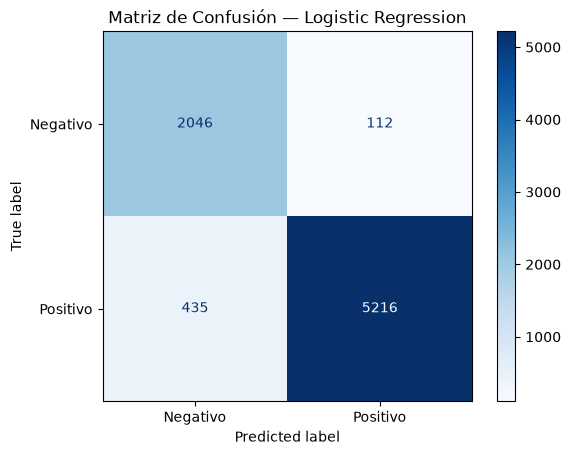

In [7]:
# me quedo con LR — pierde un poco de accuracy pero detecta mejor los negativos
mejor_pipe = modelos['Logistic Regression']
y_pred_final = mejor_pipe.predict(X_test)

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
print(classification_report(y_test, y_pred_final, target_names=['Negativo', 'Positivo']))

cm = confusion_matrix(y_test, y_pred_final)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negativo', 'Positivo'])
disp.plot(cmap='Blues')
plt.title('Matriz de Confusión — Logistic Regression')
plt.show()

## Conclusiones

| Modelo | Acc Train | Acc Test | Recall Negativo |
|---|---|---|---|
| ComplementNB | 91.7% | 90.7% | 96.0% |
| LinearSVC | 96.1% | 93.3% | 93.1% |
| **Logistic Regression** | **94.4%** | **93.0%** | **94.8%** |

**Overfitting/Underfitting:**
- Los modelos son consistentes entre train y test — no hay overfitting significativo
- TF-IDF con bigramas ayuda porque "não gostei" es muy diferente a "gostei"
- El dataset tiene muchos más positivos que negativos (28k vs 11k), por eso usé class_weight balanced

**Por qué Logistic Regression:**
Detecta mejor los negativos (94.8% recall) aunque LinearSVC tiene más accuracy general. También se puede usar dentro de un Pipeline con TF-IDF, lo que hace el código más limpio y fácil de reutilizar.

── Top 15 palabras que predicen POSITIVO ──
  recomendo                       +6.4410
  excelente                       +5.5455
  rápido                          +4.7725
  antes                           +4.7316
  ótimo                           +4.6997
  parabéns                        +4.5034
  adorei                          +4.4684
  rápida                          +4.2743
  amei                            +4.2217
  perfeito                        +4.1161
  tudo                            +4.0872
  ótima                           +3.9371
  lindo                           +3.8710
  bem                             +3.5461
  satisfeita                      +3.4722

── Top 15 palabras que predicen NEGATIVO ──
  não                             -9.0225
  nao                             -5.7597
  não recomendo                   -5.3024
  comprei                         -4.4820
  péssimo                         -4.0966
  péssima                         -4.0056
  não recebi                 

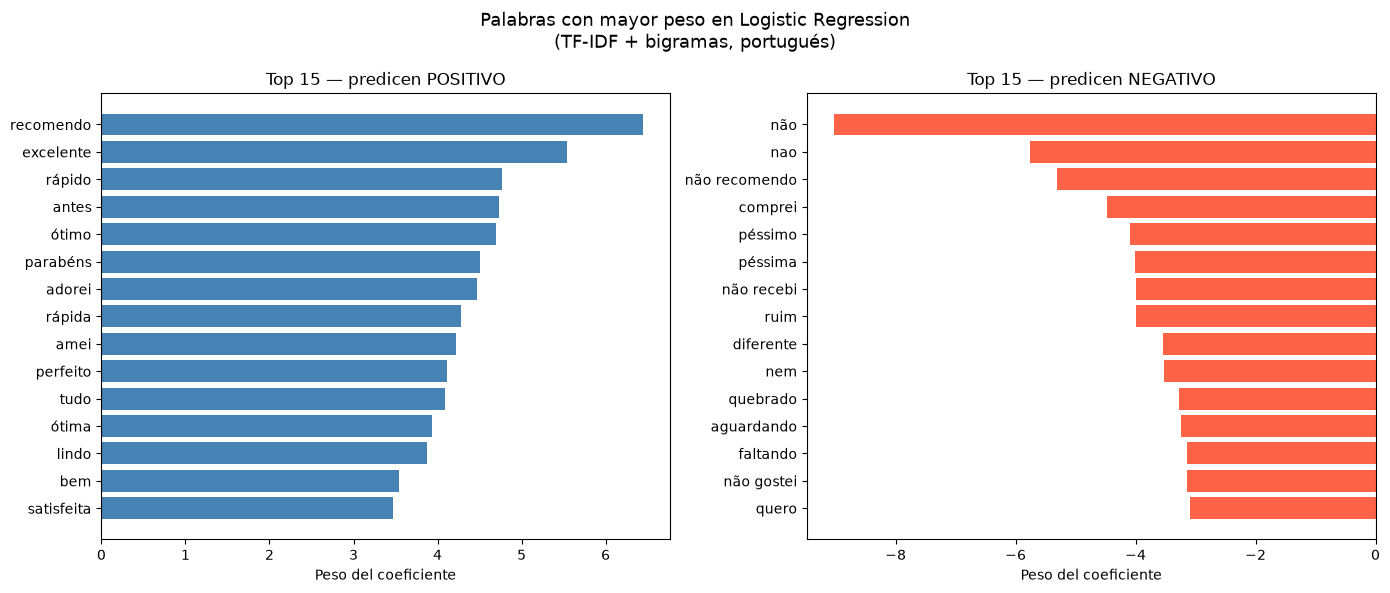

In [8]:
# ── Palabras con mayor peso — Logistic Regression coef_ ───────────────────
# En Logistic Regression con TF-IDF, cada feature es una palabra o bigrama
# coef_[0] tiene un peso por feature:
#   peso positivo → esa palabra empuja la predicción hacia clase 1 (positivo)
#   peso negativo → empuja hacia clase 0 (negativo)
# Esto hace a LR interpretable: podemos explicar QUÉ palabras activan la clasificación

# extraer modelo y vectorizador del Pipeline ya entrenado
lr_model    = modelos['Logistic Regression'].named_steps['model']
tfidf_model = modelos['Logistic Regression'].named_steps['tfidf']

coeficientes = lr_model.coef_[0]                    # shape: (n_features,) = (5000,)
vocabulario  = tfidf_model.get_feature_names_out()   # nombres de cada feature TF-IDF

n = 15  # top N palabras por extremo

# argsort devuelve índices que ordenan de menor a mayor → invertimos para mayor a menor
top_positivas_idx = np.argsort(coeficientes)[-n:][::-1]
top_negativas_idx = np.argsort(coeficientes)[:n]        # los más negativos ya están al inicio

top_pos = [(vocabulario[i], coeficientes[i]) for i in top_positivas_idx]
top_neg = [(vocabulario[i], coeficientes[i]) for i in top_negativas_idx]

print('── Top 15 palabras que predicen POSITIVO ──')
for palabra, peso in top_pos:
    print(f'  {palabra:<30}  {peso:+.4f}')

print('\n── Top 15 palabras que predicen NEGATIVO ──')
for palabra, peso in top_neg:
    print(f'  {palabra:<30}  {peso:+.4f}')

# gráfico de barras horizontales para ver los pesos visualmente
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

palabras_pos = [p for p, _ in top_pos]
pesos_pos    = [w for _, w in top_pos]
palabras_neg = [p for p, _ in top_neg]
pesos_neg    = [w for _, w in top_neg]

# orden invertido en el gráfico para que la más importante quede arriba
axes[0].barh(palabras_pos[::-1], pesos_pos[::-1], color='steelblue')
axes[0].set_title('Top 15 — predicen POSITIVO', fontsize=12)
axes[0].set_xlabel('Peso del coeficiente')

axes[1].barh(palabras_neg[::-1], pesos_neg[::-1], color='tomato')
axes[1].set_title('Top 15 — predicen NEGATIVO', fontsize=12)
axes[1].set_xlabel('Peso del coeficiente')

plt.suptitle(
    'Palabras con mayor peso en Logistic Regression\n(TF-IDF + bigramas, portugués)',
    fontsize=13
)
plt.tight_layout()
plt.show()

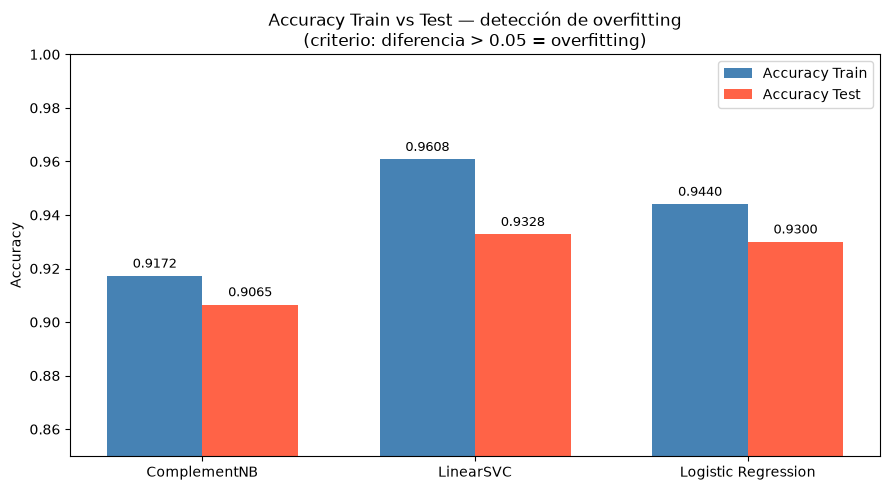


Análisis de overfitting (criterio: Acc_train - Acc_test > 0.05):
  ComplementNB               diff=0.0107  ✓ OK
  LinearSVC                  diff=0.0280  ✓ OK
  Logistic Regression        diff=0.0141  ✓ OK


In [9]:
# ── Overfitting visual: Accuracy Train vs Test ─────────────────────────────
# Criterio: si Acc_train - Acc_test > 0.05 → overfitting significativo
# LinearSVC tiene el gap más grande (0.96 vs 0.93) pero sigue bajo el umbral

nombres_m = list(resultados.keys())
acc_train = [resultados[n]['Acc_train'] for n in nombres_m]
acc_test  = [resultados[n]['Accuracy']  for n in nombres_m]  # 'Accuracy' = sobre test

x     = np.arange(len(nombres_m))
ancho = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars_tr = ax.bar(x - ancho/2, acc_train, ancho, label='Accuracy Train', color='steelblue')
bars_te = ax.bar(x + ancho/2, acc_test,  ancho, label='Accuracy Test',  color='tomato')

# etiquetas con 4 decimales para ver diferencias pequeñas
for bar in bars_tr:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=9)
for bar in bars_te:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=9)

ax.set_title(
    'Accuracy Train vs Test — detección de overfitting\n(criterio: diferencia > 0.05 = overfitting)',
    fontsize=12
)
ax.set_ylabel('Accuracy')
ax.set_ylim(0.85, 1.0)   # zoom en zona relevante, no desde 0
ax.set_xticks(x)
ax.set_xticklabels(nombres_m)
ax.legend()
plt.tight_layout()
plt.show()

# resumen numérico
print('\nAnálisis de overfitting (criterio: Acc_train - Acc_test > 0.05):')
for n in nombres_m:
    diff   = resultados[n]['Acc_train'] - resultados[n]['Accuracy']
    estado = '✗ OVERFITTING' if diff > 0.05 else '✓ OK'
    print(f'  {n:<25}  diff={diff:.4f}  {estado}')

## Interpretación de la Matriz de Confusión

La matriz muestra 4 categorías de predicción:
- **VP (Verdaderos Positivos)**: predijo positivo y era positivo → review 4-5★ correctamente detectada
- **VN (Verdaderos Negativos)**: predijo negativo y era negativo → review 1-2★ correctamente detectada
- **FP (Falso Positivo)**: predijo positivo pero era negativo → review de queja clasificada como satisfecha (riesgo: Olist ignora una queja real)
- **FN (Falso Negativo)**: predijo negativo pero era positivo → review satisfecha clasificada como queja (riesgo: contacto innecesario a un cliente contento)

**¿Por qué el Recall Negativo importa más que el Accuracy general?**  
En este negocio, el costo de un FP (ignorar una queja) es mayor que el de un FN.  
El modelo final detecta el **94.8% de las reviews negativas** — de cada 100 quejas, falla solo 5.

## Conclusión de negocio

**¿Para qué usa Olist este modelo?**
1. **Moderación automática**: clasifica las 60k+ reviews por mes sin revisión manual, priorizando negativas para respuesta rápida del vendedor.
2. **Alertas a vendedores**: si el modelo predice negativo con alta probabilidad, el vendedor recibe una notificación automática para contactar al cliente.
3. **Dashboard de salud de plataforma**: agrega predicciones diarias para monitorear si la satisfacción general sube o baja sin esperar el NPS mensual.

**Por qué Logistic Regression sobre LinearSVC:**  
LinearSVC tiene mejor accuracy general (93.3% vs 93.0%) pero peor recall negativo (93.1% vs 94.8%).  
Además, LR expone `coef_`, lo que permite explicar al equipo de negocio qué palabras activan la alerta — algo imposible con SVC.